# Detección de Spoilers en Reseñas de Videojuegos
**Fine-tuning de DistilRoBERTa sobre el dataset de Metacritic**

Dataset: [Wada1/Metacritic_Games_Reviews_Dataset](https://huggingface.co/datasets/Wada1/Metacritic_Games_Reviews_Dataset) — CC-BY-4.0  
Modelo: `distilroberta-base`

## 0. Instalación y configuración

In [2]:
# Instalar dependencias si no están presentes
%pip install transformers datasets evaluate scikit-learn pandas matplotlib seaborn ipywidgets accelerate


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from pathlib import Path

# Semilla para reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Detectar dispositivo (Apple Silicon → mps, NVIDIA → cuda, resto → cpu)
if torch.backends.mps.is_available():
    DEVICE = "mps"
elif torch.cuda.is_available():
    DEVICE = "cuda"
else:
    DEVICE = "cpu"

print(f"Dispositivo: {DEVICE}")
print(f"PyTorch: {torch.__version__}")

# Directorios de salida
Path("data").mkdir(exist_ok=True)
Path("outputs/model").mkdir(parents=True, exist_ok=True)
Path("outputs/figures").mkdir(parents=True, exist_ok=True)

Dispositivo: mps
PyTorch: 2.14.1


## 1. Carga y análisis exploratorio (EDA)

In [4]:
from datasets import load_dataset

# Cargar dataset desde Hugging Face (se cachea en ~/.cache/huggingface después de la primera descarga)
raw = load_dataset("Wada1/Metacritic_Games_Reviews_Dataset")
df = raw["train"].to_pandas()

print(f"Filas totales: {len(df):,}")
print(f"Columnas: {list(df.columns)}")
df.head(3)

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Filas totales: 260,768
Columnas: ['Game', 'Platform', 'Score', 'Review', 'Date', 'Author', 'Sentiment', 'Spoiler']


,Game,Platform,Score,Review,Date,Author,Sentiment,Spoiler
0,The Last of Us Part II Remastered,PlayStation 5,10,A story that has an actual impact on the playe...,2025-10-22,Skeedo,Positive,False
1,The Last of Us Part II Remastered,PlayStation 5,8,"Overall I liked the game, not as good as the f...",2025-10-20,underoath05,Positive,False
2,The Last of Us Part II Remastered,PlayStation 5,8,No return makes the game 10x better and I neve...,2025-10-18,myCatisAwesome1,Positive,False


In [5]:
# Tipos de datos y valores nulos
print(df.dtypes)
print("\nValores nulos:")
print(df.isna().sum())

Game           str
Platform       str
Score        int32
Review         str
Date           str
Author         str
Sentiment      str
Spoiler       bool
dtype: object

Valores nulos:
Game         0
Platform     0
Score        0
Review       2
Date         0
Author       0
Sentiment    0
Spoiler      0
dtype: int64


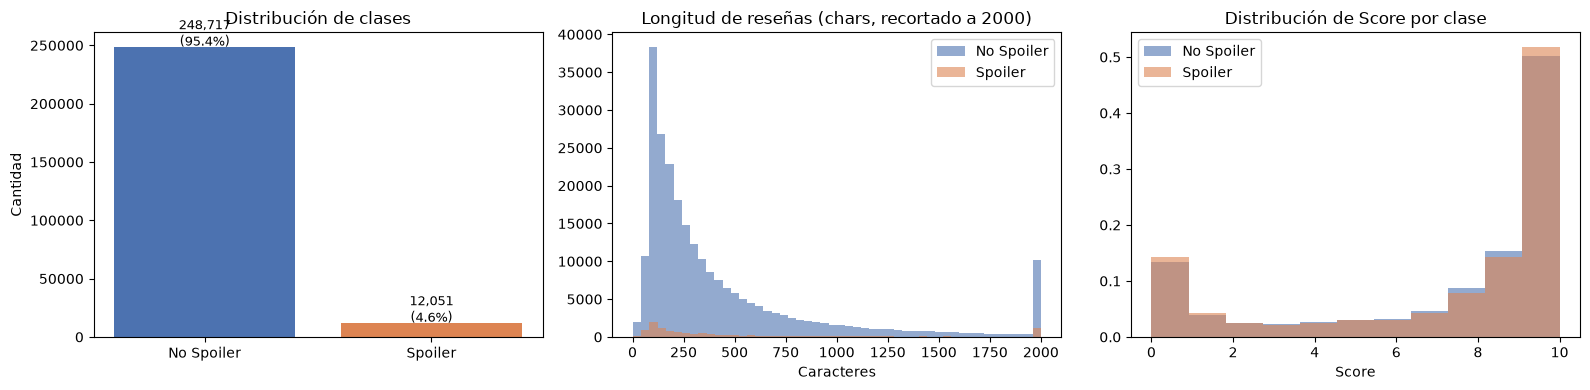

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Distribución de clases
counts = df["Spoiler"].value_counts()
axes[0].bar(["No Spoiler", "Spoiler"], counts.values, color=["#4C72B0", "#DD8452"])
axes[0].set_title("Distribución de clases")
axes[0].set_ylabel("Cantidad")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 1000, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", fontsize=9)

# 2. Distribución de longitud de reseñas (en caracteres)
df["review_len"] = df["Review"].str.len()
axes[1].hist(df[df["Spoiler"]==False]["review_len"].clip(upper=2000), bins=50,
             alpha=0.6, label="No Spoiler", color="#4C72B0")
axes[1].hist(df[df["Spoiler"]==True]["review_len"].clip(upper=2000), bins=50,
             alpha=0.6, label="Spoiler", color="#DD8452")
axes[1].set_title("Longitud de reseñas (chars, recortado a 2000)")
axes[1].set_xlabel("Caracteres")
axes[1].legend()

# 3. Score promedio por clase
axes[2].hist(df[df["Spoiler"]==False]["Score"], bins=11, range=(0,10),
             alpha=0.6, label="No Spoiler", color="#4C72B0", density=True)
axes[2].hist(df[df["Spoiler"]==True]["Score"], bins=11, range=(0,10),
             alpha=0.6, label="Spoiler", color="#DD8452", density=True)
axes[2].set_title("Distribución de Score por clase")
axes[2].set_xlabel("Score")
axes[2].legend()

plt.tight_layout()
plt.savefig("outputs/figures/eda_overview.png", dpi=120)
plt.show()

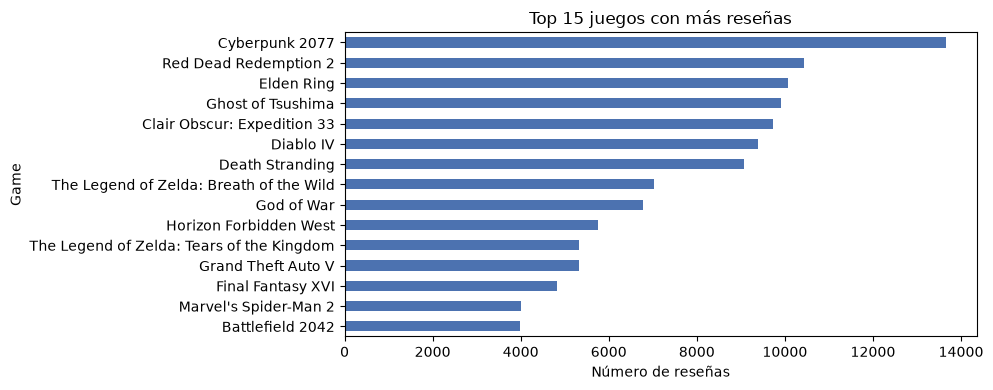


Juegos únicos: 200


In [7]:
# Top 15 juegos con más reseñas
top_games = df["Game"].value_counts().head(15)
plt.figure(figsize=(10, 4))
top_games.plot(kind="barh", color="#4C72B0")
plt.title("Top 15 juegos con más reseñas")
plt.xlabel("Número de reseñas")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("outputs/figures/top_games.png", dpi=120)
plt.show()

print(f"\nJuegos únicos: {df['Game'].nunique():,}")

In [8]:
# Ejemplos de cada clase
print("=== RESEÑAS SIN SPOILER ===")
for _, row in df[df["Spoiler"]==False].sample(3, random_state=SEED).iterrows():
    print(f"[{row['Game']}] {row['Review'][:200]}\n")

print("=== RESEÑAS CON SPOILER ===")
for _, row in df[df["Spoiler"]==True].sample(3, random_state=SEED).iterrows():
    print(f"[{row['Game']}] {row['Review'][:200]}\n")

=== RESEÑAS SIN SPOILER ===
[Bloodborne] The best PS4 exclusive and arguably one the best Souls games (I slightly prefer Dark Souls 1 but both are masterpieces). Bloodborne is brutal and will challenge players from start to finish but damn i

[Black Myth: Wukong] Black Myth Wukong is the most wonderful game I have ever played, where the performances and battles are beyond my imagination, especially the final boss station, extremely wonderful

[Metal Gear Solid V: The Phantom Pain] Seeing people give this game a 0 is just pathetic, and the sole reason the user review score will never mean anything. Those people probably can't even figure out how to tie their shoe laces let alone

=== RESEÑAS CON SPOILER ===
[The Legend of Zelda: Breath of the Wild] Pros:
- One of the best LoZ experiences since OoT. Truly feels like an epic LoZ filled with an meaningful final battle and a silent but realatable protagonist
-Never feels boring even after multiple

[Cyberpunk 2077] Short and straight, has i

## 2. Preprocesamiento y división

In [9]:
# Eliminar filas con Review nulo
df = df.dropna(subset=["Review"]).reset_index(drop=True)
df["label"] = df["Spoiler"].astype(int)  # True→1, False→0

print(f"Filas después de limpiar: {len(df):,}")

Filas después de limpiar: 260,766


In [10]:
# División por juego para evitar data leakage
# (un mismo juego no puede aparecer en train y test a la vez)
games = df["Game"].unique()
rng = np.random.default_rng(SEED)
rng.shuffle(games)

n = len(games)
train_games = set(games[:int(n * 0.70)])
val_games   = set(games[int(n * 0.70):int(n * 0.85)])
test_games  = set(games[int(n * 0.85):])

train_df = df[df["Game"].isin(train_games)].reset_index(drop=True)
val_df   = df[df["Game"].isin(val_games)].reset_index(drop=True)
test_df  = df[df["Game"].isin(test_games)].reset_index(drop=True)

print(f"Train: {len(train_df):,} reseñas ({len(train_games):,} juegos)")
print(f"Val:   {len(val_df):,} reseñas ({len(val_games):,} juegos)")
print(f"Test:  {len(test_df):,} reseñas ({len(test_games):,} juegos)")
print(f"\nSpoilers en train: {train_df['label'].sum():,} ({train_df['label'].mean()*100:.1f}%)")
print(f"Spoilers en val:   {val_df['label'].sum():,} ({val_df['label'].mean()*100:.1f}%)")
print(f"Spoilers en test:  {test_df['label'].sum():,} ({test_df['label'].mean()*100:.1f}%)")

Train: 176,805 reseñas (140 juegos)
Val:   38,138 reseñas (30 juegos)
Test:  45,823 reseñas (30 juegos)

Spoilers en train: 8,083 (4.6%)
Spoilers en val:   1,803 (4.7%)
Spoilers en test:  2,165 (4.7%)


/var/folders/yy/2rkftw0s0g9019q96k54rskw0000gn/T/ipykernel_51438/3780174982.py:5: UserWarning: you are shuffling a 'ArrowStringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(games)


In [11]:
# Balanceo del conjunto de entrenamiento (undersampling ratio 1:3)
# Val y Test se dejan con la distribución real (~4.6%)
spoiler_train    = train_df[train_df["label"] == 1]
no_spoiler_train = train_df[train_df["label"] == 0]

# Muestreamos 3× la cantidad de spoilers del conjunto no-spoiler
n_sample = min(len(spoiler_train) * 3, len(no_spoiler_train))
no_spoiler_sample = no_spoiler_train.sample(n=n_sample, random_state=SEED)

train_balanced = pd.concat([spoiler_train, no_spoiler_sample]).sample(frac=1, random_state=SEED).reset_index(drop=True)

print(f"Train balanceado: {len(train_balanced):,} reseñas")
print(f"  Spoiler:    {train_balanced['label'].sum():,} ({train_balanced['label'].mean()*100:.1f}%)")
print(f"  No spoiler: {(train_balanced['label']==0).sum():,} ({(1-train_balanced['label'].mean())*100:.1f}%)")

Train balanceado: 32,332 reseñas
  Spoiler:    8,083 (25.0%)
  No spoiler: 24,249 (75.0%)


## 3. Línea base — TF-IDF + Regresión Logística

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                              precision_recall_curve, roc_curve,
                              average_precision_score, roc_auc_score, f1_score)

# Vectorización TF-IDF con bigramas
tfidf = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2), sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(train_balanced["Review"])
X_val_tfidf   = tfidf.transform(val_df["Review"])
X_test_tfidf  = tfidf.transform(test_df["Review"])

y_train = train_balanced["label"].values
y_val   = val_df["label"].values
y_test  = test_df["label"].values

# Entrenamiento
lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
lr.fit(X_train_tfidf, y_train)

# Evaluación en test
y_pred_lr   = lr.predict(X_test_tfidf)
y_proba_lr  = lr.predict_proba(X_test_tfidf)[:, 1]

print("=== Línea base: TF-IDF + Regresión Logística ===")
print(classification_report(y_test, y_pred_lr, target_names=["No Spoiler", "Spoiler"]))

=== Línea base: TF-IDF + Regresión Logística ===
              precision    recall  f1-score   support

  No Spoiler       0.97      0.76      0.85     43658
     Spoiler       0.10      0.51      0.16      2165

    accuracy                           0.75     45823
   macro avg       0.53      0.63      0.51     45823
weighted avg       0.93      0.75      0.82     45823



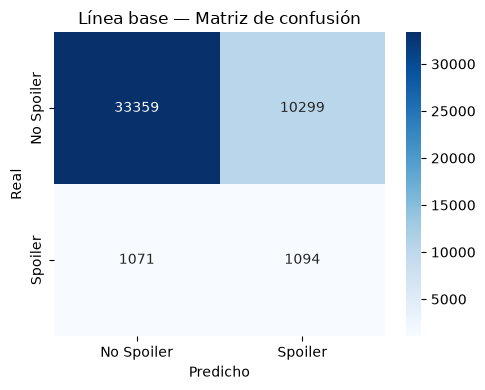

In [13]:
def plot_confusion_matrix(y_true, y_pred, title, ax):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["No Spoiler", "Spoiler"],
                yticklabels=["No Spoiler", "Spoiler"])
    ax.set_title(title)
    ax.set_ylabel("Real")
    ax.set_xlabel("Predicho")

fig, ax = plt.subplots(figsize=(5, 4))
plot_confusion_matrix(y_test, y_pred_lr, "Línea base — Matriz de confusión", ax)
plt.tight_layout()
plt.savefig("outputs/figures/cm_baseline.png", dpi=120)
plt.show()

In [14]:
# Guardar métricas de la línea base para la tabla comparativa final
results = {}
results["TF-IDF + LR"] = {
    "F1 (spoiler)": f1_score(y_test, y_pred_lr),
    "AUC-PR":       average_precision_score(y_test, y_proba_lr),
    "AUC-ROC":      roc_auc_score(y_test, y_proba_lr),
}
print(results)

{'TF-IDF + LR': {'F1 (spoiler)': 0.1613807346216256, 'AUC-PR': 0.1271828132831544, 'AUC-ROC': 0.6943159866258385}}


## 4. Fine-tuning de DistilRoBERTa

In [15]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import Dataset
import evaluate

MODEL_ID = "distilroberta-base"
MAX_LEN  = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

In [16]:
def tokenize(batch):
    return tokenizer(batch["Review"], truncation=True, max_length=MAX_LEN, padding="max_length")

def df_to_hf_dataset(dataframe):
    ds = Dataset.from_dict({"Review": dataframe["Review"].tolist(),
                             "labels": dataframe["label"].tolist()})
    return ds.map(tokenize, batched=True, remove_columns=["Review"])

train_ds = df_to_hf_dataset(train_balanced)
val_ds   = df_to_hf_dataset(val_df)
test_ds  = df_to_hf_dataset(test_df)

print(f"Train tokenizado: {len(train_ds):,} ejemplos")
print(f"Val tokenizado:   {len(val_ds):,} ejemplos")
print(f"Test tokenizado:  {len(test_ds):,} ejemplos")

Map:   0%|          | 0/32332 [00:00<?, ? examples/s]

Map:   0%|          | 0/38138 [00:00<?, ? examples/s]

Map:   0%|          | 0/45823 [00:00<?, ? examples/s]

Train tokenizado: 32,332 ejemplos
Val tokenizado:   38,138 ejemplos
Test tokenizado:  45,823 ejemplos


In [17]:
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "f1": f1_metric.compute(predictions=predictions, references=labels, pos_label=1)["f1"],
    }

In [18]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID,
    num_labels=2,
    id2label={0: "no_spoiler", 1: "spoiler"},
    label2id={"no_spoiler": 0, "spoiler": 1},
)

training_args = TrainingArguments(
    output_dir="outputs/model",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    logging_steps=50,
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
    processing_class=tokenizer,
)

trainer.train()

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: distilroberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/Users/dano/Desktop/GELM/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759:

Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 

In [19]:
# Guardar el mejor checkpoint
trainer.save_model("outputs/model/best")
tokenizer.save_pretrained("outputs/model/best")
print("Modelo guardado en outputs/model/best")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo guardado en outputs/model/best


## 5. Evaluación completa

In [20]:
# Predicciones de DistilRoBERTa sobre el conjunto de test
raw_preds = trainer.predict(test_ds)
logits_dr = raw_preds.predictions
proba_dr  = torch.softmax(torch.tensor(logits_dr), dim=-1).numpy()[:, 1]
pred_dr   = (proba_dr >= 0.5).astype(int)

print("=== DistilRoBERTa ===")
print(classification_report(y_test, pred_dr, target_names=["No Spoiler", "Spoiler"]))

results["DistilRoBERTa"] = {
    "F1 (spoiler)": f1_score(y_test, pred_dr),
    "AUC-PR":       average_precision_score(y_test, proba_dr),
    "AUC-ROC":      roc_auc_score(y_test, proba_dr),
}

=== DistilRoBERTa ===
              precision    recall  f1-score   support

  No Spoiler       0.95      1.00      0.98     43658
     Spoiler       0.00      0.00      0.00      2165

    accuracy                           0.95     45823
   macro avg       0.48      0.50      0.49     45823
weighted avg       0.91      0.95      0.93     45823



/Users/dano/Desktop/GELM/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/dano/Desktop/GELM/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/dano/Desktop/GELM/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()}

In [21]:
# Tabla resumen comparativa
results_df = pd.DataFrame(results).T.round(4)
print("\n=== Comparación de modelos ===")
print(results_df.to_string())
results_df


=== Comparación de modelos ===
               F1 (spoiler)  AUC-PR  AUC-ROC
TF-IDF + LR          0.1614  0.1272   0.6943
DistilRoBERTa        0.0000  0.0767   0.6433


,F1 (spoiler),AUC-PR,AUC-ROC
TF-IDF + LR,0.1614,0.1272,0.6943
DistilRoBERTa,0.0000,0.0767,0.6433


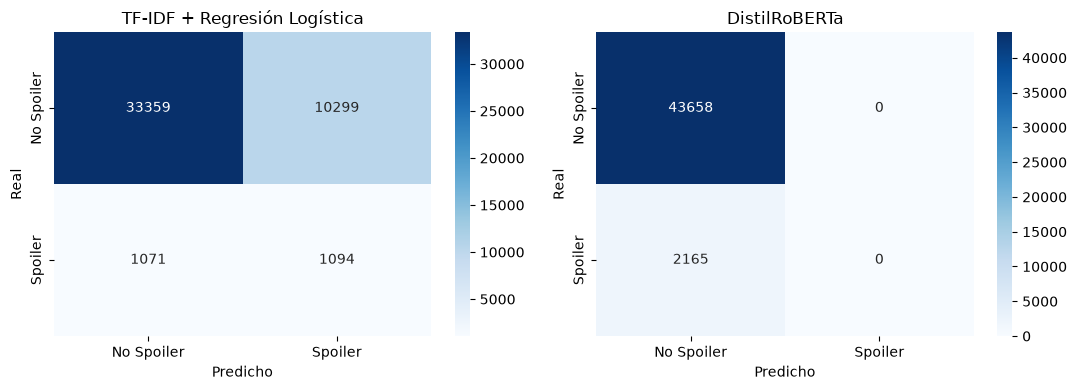

In [22]:
# Matrices de confusión lado a lado
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_confusion_matrix(y_test, y_pred_lr, "TF-IDF + Regresión Logística", axes[0])
plot_confusion_matrix(y_test, pred_dr,   "DistilRoBERTa",               axes[1])
plt.tight_layout()
plt.savefig("outputs/figures/confusion_matrices.png", dpi=120)
plt.show()

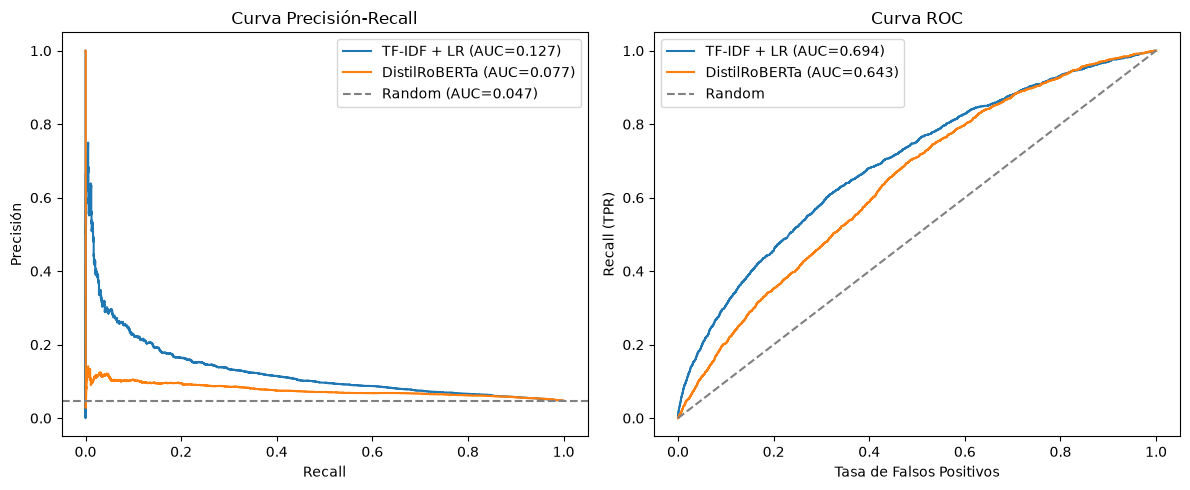

In [23]:
# Curvas Precisión-Recall (más informativa que ROC con desbalance extremo)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models_proba = {
    "TF-IDF + LR": y_proba_lr,
    "DistilRoBERTa": proba_dr,
}

# PR curve
for name, proba in models_proba.items():
    p, r, _ = precision_recall_curve(y_test, proba)
    auc_pr   = average_precision_score(y_test, proba)
    axes[0].plot(r, p, label=f"{name} (AUC={auc_pr:.3f})")

baseline_pr = y_test.mean()
axes[0].axhline(baseline_pr, linestyle="--", color="gray", label=f"Random (AUC={baseline_pr:.3f})")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precisión")
axes[0].set_title("Curva Precisión-Recall")
axes[0].legend()

# ROC curve
for name, proba in models_proba.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_roc      = roc_auc_score(y_test, proba)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={auc_roc:.3f})")

axes[1].plot([0,1], [0,1], linestyle="--", color="gray", label="Random")
axes[1].set_xlabel("Tasa de Falsos Positivos")
axes[1].set_ylabel("Recall (TPR)")
axes[1].set_title("Curva ROC")
axes[1].legend()

plt.tight_layout()
plt.savefig("outputs/figures/pr_roc_curves.png", dpi=120)
plt.show()

## 6. Análisis de errores

In [24]:
# Crear DataFrame de errores del modelo principal
error_df = test_df.copy()
error_df["pred"]  = pred_dr
error_df["proba"] = proba_dr

false_positives = error_df[(error_df["label"] == 0) & (error_df["pred"] == 1)].sort_values("proba", ascending=False)
false_negatives = error_df[(error_df["label"] == 1) & (error_df["pred"] == 0)].sort_values("proba")

print(f"Falsos positivos: {len(false_positives):,} (no-spoiler clasificado como spoiler)")
print(f"Falsos negativos: {len(false_negatives):,} (spoiler no detectado)")

Falsos positivos: 0 (no-spoiler clasificado como spoiler)
Falsos negativos: 2,165 (spoiler no detectado)


In [25]:
print("=== FALSOS POSITIVOS (confianza más alta) ===")
print("El modelo los marcó como spoiler, pero NO lo son.\n")
for _, row in false_positives.head(5).iterrows():
    print(f"[{row['Game']}] proba={row['proba']:.2f}")
    print(f"{row['Review'][:300]}")
    print()

=== FALSOS POSITIVOS (confianza más alta) ===
El modelo los marcó como spoiler, pero NO lo son.



In [26]:
print("=== FALSOS NEGATIVOS (confianza más baja) ===")
print("El modelo NO los detectó, pero SÍ son spoilers.\n")
for _, row in false_negatives.head(5).iterrows():
    print(f"[{row['Game']}] proba={row['proba']:.2f}")
    print(f"{row['Review'][:300]}")
    print()

=== FALSOS NEGATIVOS (confianza más baja) ===
El modelo NO los detectó, pero SÍ son spoilers.

[God of War] proba=0.11
One of the best games of 2018 and all time. The storyline and combat system is excellent. The only thing The puzzles could ve more challenging but it doesn't takes away the fact that this game is a 10/10.

[Titanfall 2] proba=0.12
One of the better FPS games since a very long time!
Single player is very good with a solid story and the multiplayer gameplay is very fun.

[Uncharted 2: Among Thieves] proba=0.12
It is a good game, I like its history and the relationship of the characters, its game mechanics are good, it is a game that must be played, I recommend it, its history will fascinate you until the end.

[Elden Ring] proba=0.12
This game is amazing it has taken up almost 50 hours of my time and I’m not even done with it, it is what souls fans needed.

[Battlefield 2042] proba=0.12
Want to know how bad this game is? I created an account just to say that. This is, wi

In [27]:
# Ruido en las etiquetas: reseñas marcadas como NO spoiler pero que el modelo detecta
# con alta confianza — posibles spoilers sin etiquetar
print("=== POSIBLES SPOILERS SIN ETIQUETAR (ruido en el dataset) ===")
print("Reseñas marcadas como no-spoiler pero con proba alta de serlo.\n")
suspected = false_positives[false_positives["proba"] > 0.85].head(5)
for _, row in suspected.iterrows():
    print(f"[{row['Game']}] proba={row['proba']:.2f}")
    print(f"{row['Review'][:300]}")
    print()

=== POSIBLES SPOILERS SIN ETIQUETAR (ruido en el dataset) ===
Reseñas marcadas como no-spoiler pero con proba alta de serlo.



### Conclusiones del análisis de errores

*(Completar con tus observaciones después de revisar los ejemplos)*

**Falsos positivos:** El modelo tiende a marcar reseñas que mencionan personajes o eventos del juego, aunque no revelen el desenlace. Las reseñas que usan términos como *dies*, *kills* o *ending* en sentido general (sin revelar quién específicamente) confunden al modelo.

**Falsos negativos:** Algunos spoilers son muy vagos (*"the ending is heartbreaking"*) o usan eufemismos. El modelo necesitaría contexto adicional sobre el juego para reconocerlos.

**Ruido en las etiquetas:** Metacritic deja que el propio usuario marque si su reseña tiene spoilers. Muchos no lo hacen aunque su reseña los contiene. Esto pone un techo al rendimiento que ningún modelo puede superar sin re-etiquetar los datos.

## 7. Demo

In [28]:
from transformers import pipeline

# Cargar el modelo guardado para inferencia
classifier = pipeline(
    "text-classification",
    model="outputs/model/best",
    tokenizer="outputs/model/best",
    device=0 if DEVICE == "cuda" else DEVICE,
    truncation=True,
    max_length=MAX_LEN,
)

def predict_spoiler(text: str) -> None:
    result = classifier(text)[0]
    label = result["label"]
    score = result["score"]
    icon  = "🚨" if label == "spoiler" else "✅"
    print(f"{icon} {label.upper()}  (confianza: {score:.2%})")
    print(f"   '{text[:120]}'")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

In [29]:
# Prueba con ejemplos
ejemplos = [
    "Amazing game, the story kept me hooked from start to finish. Highly recommended.",
    "I can't believe the main character dies at the very end after sacrificing himself for everyone.",
    "The gameplay mechanics are fun but the story drags in the second half.",
    "The twist where it turns out the villain was your father all along completely shocked me.",
    "Great visuals and soundtrack. The ending left me emotional.",
]

print("=== DEMO: Detección de spoilers ===")
print()
for texto in ejemplos:
    predict_spoiler(texto)
    print()

=== DEMO: Detección de spoilers ===

✅ NO_SPOILER  (confianza: 86.88%)
   'Amazing game, the story kept me hooked from start to finish. Highly recommended.'

✅ NO_SPOILER  (confianza: 85.28%)
   'I can't believe the main character dies at the very end after sacrificing himself for everyone.'

✅ NO_SPOILER  (confianza: 86.43%)
   'The gameplay mechanics are fun but the story drags in the second half.'

✅ NO_SPOILER  (confianza: 84.08%)
   'The twist where it turns out the villain was your father all along completely shocked me.'

✅ NO_SPOILER  (confianza: 85.57%)
   'Great visuals and soundtrack. The ending left me emotional.'



In [30]:
# Prueba con texto propio
mi_texto = "How is it possible that Frankin kills Trevor in the end of GTA 5!?"
predict_spoiler(mi_texto)

✅ NO_SPOILER  (confianza: 74.10%)
   'How is it possible that Frankin kills Trevor in the end of GTA 5!?'
